# EDA revisada — Messi: anatomia do gol

Continuação da EDA fornecida, com os nomes reais das colunas e análise bivariada para os dashboards.
Uma linha é um gol registrado, não uma partida. Público do painel 2: jornalistas e produtores de conteúdo esportivo.
Autoria acadêmica: preencher antes da entrega. Assistência de IA documentada em `../prompts/`.

O arquivo `eda_original.ipynb` é uma cópia histórica do anexo, sem alterações; seus caminhos e nomes condicionais não foram corrigidos. Execute **este** notebook a partir da pasta `notebooks/` ou da raiz do projeto.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd() if (Path.cwd() / 'app.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.dados import RAW, CLEAN, NUMERICAS, preparar, calcular_kpis, contar
sns.set_theme(style='whitegrid', palette=['#167d9a', '#9c516c'])
original = pd.read_csv(RAW)
df = preparar(original)
# Exportação explícita dos dataframes original e tratado, como solicitado nas aulas.
original.to_csv(RAW, index=False, encoding='utf-8-sig')
df.to_csv(CLEAN, index=False, date_format='%Y-%m-%d')
print(f'Original: {original.shape}; tratado: {df.shape}')
df.head()

Original: (790, 16); tratado: (790, 19)


,competition,match_stage,date,venue,club,opponent,match_score,player_position,goal_minute,score_at_goal,goal_type,assist_player,season,goal_decade,is_home_goal,goal_minute_bucket,year,match_total_goals,score_total_at_goal
0,2ª B - Grupo III,2,2004-09-05,Home,FC Barcelona B,Girona FC,1:2,LW,65,1:2,Left-footed shot,Dani Fernández,2004-05,2000s,True,61-75,2004,3,3
1,2ª B - Grupo III,4,2004-09-18,Home,FC Barcelona B,RCD Espanyol B,2:0,LW,88,2:0,Left-footed shot,Dani Fernández,2004-05,2000s,True,76-90,2004,2,2
2,2ª B - Grupo III,10,2004-10-31,Away,FC Barcelona B,Villajoyosa CF,2:1,AM,2,0:1,Não informado,Sem assistência registrada,2004-05,2000s,False,0-15,2004,3,1
3,2ª B - Grupo III,14,2004-11-28,Away,FC Barcelona B,UE Figueres,2:2,AM,20,0:1,Não informado,Sem assistência registrada,2004-05,2000s,False,16-30,2004,4,1
4,2ª B - Grupo III,17,2004-12-19,Home,FC Barcelona B,CD Alcoyano,2:0,CF,40,2:0,Left-footed shot,Sem assistência registrada,2004-05,2000s,True,31-45,2004,2,2


## Diagnóstico e limpeza

Datas convertidas com formato explícito; minutos convertidos em número; placares validados antes de somar os dois lados, sem presumir a ordem casa/fora. Nenhuma linha excluída.
`Not Applicable` em assistência significa “Sem assistência registrada”, não prova de jogada individual. `Not reported` em tipo de gol é explicitado como “Não informado”.
O notebook anterior testava `assist` e `type`, mas essas colunas não existem neste CSV. Agora são utilizadas `assist_player` e `goal_type`.

In [2]:
diagnostico = pd.DataFrame({'tipo': original.dtypes.astype(str),
                            'ausentes': original.isna().sum(),
                            'distintos': original.nunique()})
print('Duplicatas exatas:', original.duplicated().sum())
print('Período:', df.date.min().date(), 'a', df.date.max().date())
print('Assistência sem registro:', df.assist_player.eq('Sem assistência registrada').sum())
print('Tipo não informado:', df.goal_type.eq('Não informado').sum())
diagnostico

Duplicatas exatas: 0
Período: 2004-09-05 a 2026-03-07
Assistência sem registro: 240
Tipo não informado: 5


,tipo,ausentes,distintos
competition,object,0,13
match_stage,object,0,45
date,object,0,518
venue,object,0,2
club,object,0,4
opponent,object,0,125
match_score,object,0,49
player_position,object,0,5
goal_minute,int64,0,96
score_at_goal,object,0,39


## Distribuição das quantitativas

Variáveis avaliadas: minuto registrado, total no placar final, total no placar após o gol e ano. As duas somas dos placares são derivadas quantitativas; ano é um índice temporal opcional no app. Não se codificam clubes ou competições como números.
O minuto é mantido como veio no arquivo (2 a 110); não há como distinguir de maneira confiável acréscimo e prorrogação a partir dessa codificação.

In [3]:
df[list(NUMERICAS)].rename(columns=NUMERICAS).describe().T

,count,mean,std,min,25%,50%,75%,max
Minuto registrado do gol,790.0,51.981013,26.045313,2.0,29.0,54.0,75.00,110.0
Soma do placar final informado,790.0,4.486076,1.894340,1.0,3.0,4.0,5.75,21.0
Soma do placar após o gol,790.0,2.770886,1.575128,1.0,2.0,2.0,4.00,8.0
Ano do gol,790.0,2015.160759,5.146348,2004.0,2011.0,2015.0,2019.00,2026.0


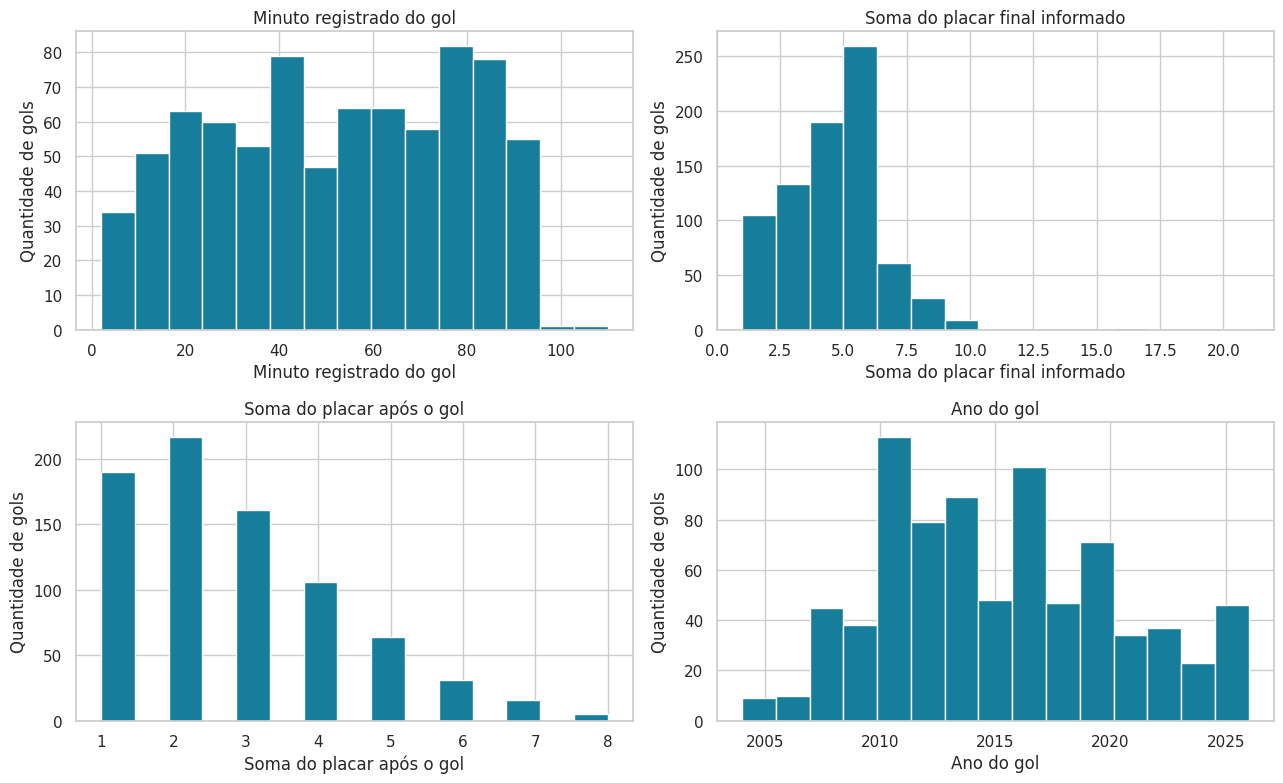

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (var, titulo) in zip(axes.flat, NUMERICAS.items()):
    ax.hist(df[var], bins=15, color='#167d9a', edgecolor='white')
    ax.set(title=titulo, xlabel=titulo, ylabel='Quantidade de gols')
fig.tight_layout()
plt.show()

## Correlação: associação, dependência e limites

Pearson descreve associação linear e Spearman a relação monotônica. Placares de uma partida aparecem repetidos em diferentes gols, e o placar após o gol faz parte do resultado final: há dependência estrutural. Não se inferem causalidade, significância ou eficiência do jogador.

Sensibilidade adicional abaixo usa uma linha por partida com gol: **média do minuto dos gols de Messi** e **total do placar final**. Essa agregação muda a unidade de análise e não elimina viés de seleção de jogos com gol.

**Qualidade dos placares:** três registros em duas partidas trazem placares finais `7:9` e `10:11`. A convenção de inclusão de disputas por pênaltis não foi documentada. As somas representam o placar informado, não um total certificado de gols no tempo jogado. Esses registros são preservados, sem corrigir por suposição.

In [5]:
df.loc[df['match_total_goals'] > 10, ['date', 'club', 'opponent', 'match_score', 'score_at_goal']]

,date,club,opponent,match_score,score_at_goal
715,2023-08-07,Inter Miami CF,FC Dallas,7:9,0:1
716,2023-08-07,Inter Miami CF,FC Dallas,7:9,4:4
719,2023-08-20,Inter Miami CF,Nashville SC,10:11,0:1


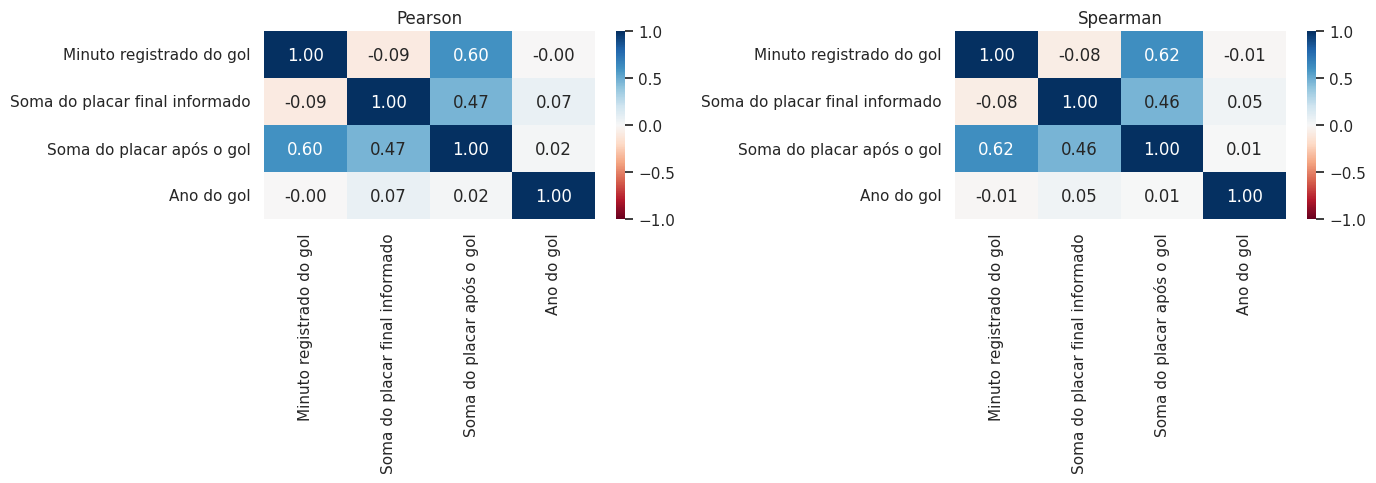

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metodo in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(df[list(NUMERICAS)].rename(columns=NUMERICAS).corr(method=metodo),
                annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu', ax=ax)
    ax.set_title(metodo.title())
fig.tight_layout()
plt.show()

In [7]:
partidas = df.groupby(['date', 'club', 'opponent', 'competition']).agg(
    minuto_medio=('goal_minute', 'mean'),
    total_placar=('match_total_goals', 'first'),
    gols_messi=('goal_minute', 'size'))
print('Partidas distintas com gol:', len(partidas))
partidas[['minuto_medio', 'total_placar']].corr()

Partidas distintas com gol: 518


,minuto_medio,total_placar
minuto_medio,1.000000,-0.116839
total_placar,-0.116839,1.000000


## KPIs para o público editorial

Quatro indicadores: gols registrados, partidas com ao menos um gol no recorte, adversários distintos e percentual de gols classificados como pênalti ou falta direta. Esses cálculos são compartilhados com o app. Denominador do percentual: todos os gols filtrados, incluindo os de tipo não informado. Rebotes de pênalti não entram no numerador.

In [8]:
kpis = calcular_kpis(df)
assert kpis['gols'] == 790
assert kpis['partidas_com_gol'] == 518
assert kpis['adversarios'] == 125
pd.Series(kpis, name='Valor')

gols                790.000000
partidas_com_gol    518.000000
adversarios         125.000000
pct_bola_parada      18.607595
Name: Valor, dtype: float64

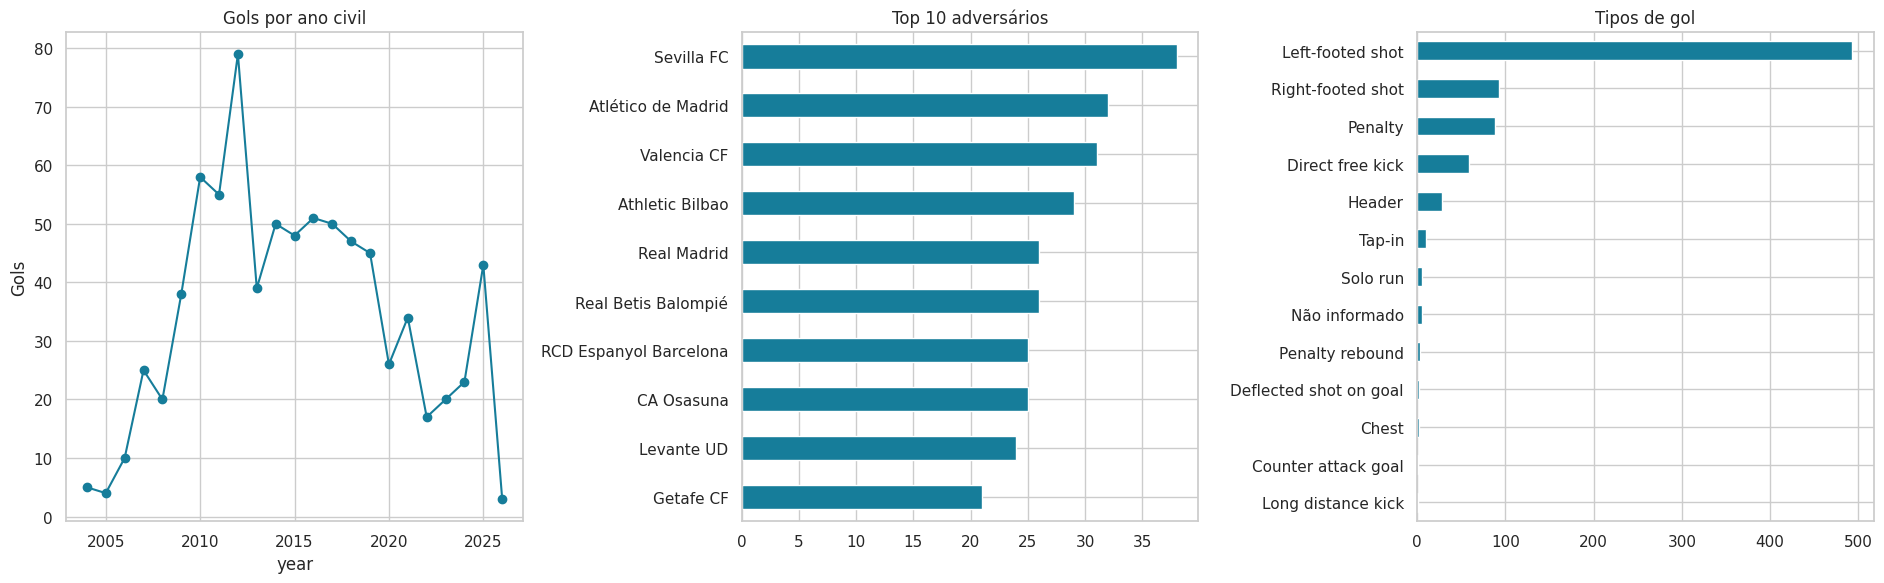

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
df.groupby('year').size().plot(ax=axes[0], marker='o', title='Gols por ano civil')
contar(df, 'opponent', 10).sort_values('Gols').plot.barh(x='opponent', y='Gols', ax=axes[1], legend=False, title='Top 10 adversários')
contar(df, 'goal_type').sort_values('Gols').plot.barh(x='goal_type', y='Gols', ax=axes[2], legend=False, title='Tipos de gol')
for ax in axes:
    ax.set_ylabel('' if ax != axes[0] else 'Gols')
fig.tight_layout()
plt.show()

## Conclusões para os dashboards

- A base fornecida tem 790 gols de clubes e 518 partidas distintas com gol, de 05/09/2004 a 07/03/2026. Não se trata de um registro de toda a carreira.
- Há 147 gols classificados como pênalti ou falta direta, 18,6% dos registros. A classificação é a do arquivo, sem reclassificar jogadas ambíguas.
- O laboratório permite observar distribuições e a sensibilidade de correlações aos filtros; relações entre placares exigem cautela.
- O painel editorial oferece três visuais: trajetória anual, adversários e tipos de gol. São contagens, sem ajuste por exposição.
- Não há jogos sem gol, chutes, minutos jogados ou informação suficiente para taxas de conversão. Não estimar gols por partida disputada a partir desta base.
- A fonte original e a licença do CSV não foram informadas no anexo; confirmar atribuição e condições de redistribuição antes de torná-lo público. Anos de borda podem ser parciais.